# SFT training: Qwen2.5-0.5B on UltraChat

**Before running**
1. Push `src/alignment/` (formatting, data, batching, losses, train_sft) to GitHub.
2. Notebook settings (right sidebar): **Accelerator = GPU T4 x2**, **Internet = On**.
3. If your repo is private, add a Kaggle secret named `GITHUB_TOKEN` (Add-ons → Secrets) containing a GitHub personal access token.

**How to use**
- **Overfit check (optional, ~2 min):** `MODE = "overfit"` trains on just 32 examples for 15 epochs. Training loss must drop by more than half, which proves the loss and optimizer path works.
- **Pilot:** keep `MODE = "pilot"` and run all cells interactively (a few minutes). Check the summary cell at the bottom.
- **Full run:** set `MODE = "full"`, then **Save Version → Save & Run All (Commit)**. It runs in the background (~1.5 h), and you can close the browser.
  When it finishes, the saved version's output (`/kaggle/working`) can be attached as an input dataset to the DPO notebook.

In [1]:
# ---- Configuration: the only cell you should need to edit ----
MODE = "full"            # "overfit", "pilot" or "full"

REPO_URL = "https://github.com/HafsaKamran/small-model-alignment-starter.git"
BRANCH = "main"
REPO_DIR = "/kaggle/working/small-model-alignment"

RUN_NAME = {"overfit": "sft_overfit", "pilot": "sft_pilot", "full": "sft"}[MODE]
OUTPUT_DIR = f"{REPO_DIR}/outputs/{RUN_NAME}"

COMMON_ARGS = ["--output_dir", OUTPUT_DIR, "--seed", "42"]
MODE_ARGS = {
    # Bug check (~2 min): memorize 32 examples over 15 epochs. Train loss must fall a lot.
    # If it doesn't, something in the loss/optimizer path is broken.
    "overfit": ["--n_train", "32", "--n_val", "32", "--epochs", "15", "--grad_accum", "1",
                "--lr", "5e-5", "--eval_every", "1000", "--log_every", "16"],
    # ~20 optimizer steps: checks loss goes down, eval runs, checkpoints save, memory fits
    "pilot": ["--n_train", "640", "--n_val", "32", "--eval_every", "10", "--log_every", "2"],
    # manual's reference recipe (all other values are train_sft.py defaults)
    "full":  ["--n_train", "30000", "--n_val", "1000", "--eval_every", "100", "--log_every", "10"],
}
EXTRA_ARGS = []           # e.g. ["--gradient_checkpointing"] if the pilot hits CUDA OOM

MAKE_ZIP = MODE == "full"  # extra copy of outputs as a single zip, per the manual's advice
assert MODE in MODE_ARGS, MODE
print(MODE, OUTPUT_DIR)

full /kaggle/working/small-model-alignment/outputs/sft


## 1. Check the GPUs

In [2]:
!nvidia-smi
import torch
print("CUDA available:", torch.cuda.is_available(), "| GPUs:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(i, torch.cuda.get_device_name(i))
assert torch.cuda.is_available(), "No GPU: set Accelerator = GPU T4 x2 in notebook settings" 

Sun Oct 11 17:49:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Clone the repository

In [3]:
import os, subprocess

url = REPO_URL
try:
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("GITHUB_TOKEN")
    url = REPO_URL.replace("https://", f"https://{token}@")
    print("Using GITHUB_TOKEN secret")
except Exception:
    print("No GITHUB_TOKEN secret; cloning as a public repo")

if os.path.isdir(os.path.join(REPO_DIR, ".git")):
    subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, url, REPO_DIR], check=True)

%cd {REPO_DIR}
!git log -1 --oneline

Using GITHUB_TOKEN secret


Cloning into '/kaggle/working/small-model-alignment'...


/kaggle/working/small-model-alignment
f7a0929 (grafted, HEAD -> main, origin/main, origin/HEAD) fix checkpointing


## 3. Install dependencies (without touching Kaggle's PyTorch)

In [4]:
!python -m pip uninstall -y -q torchao || true
!python -m pip install -q "transformers>=4.43.0,<5" "datasets>=2.18,<5" huggingface_hub accelerate tqdm pyyaml sentencepiece safetensors pytest
!python -m pip install -q -e . --no-deps || echo "editable install failed; fine, we run with python -m from the repo root" 

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 86.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for small-model-alignment-starter (pyproject.toml) ..

In [5]:
import torch, transformers, datasets
print("torch       ", torch.__version__)
print("transformers", transformers.__version__)
print("datasets    ", datasets.__version__)

torch        2.11.0+cu128
transformers 4.57.6
datasets     4.8.5


## 4. Public smoke tests (SFT parts)

In [6]:
!PYTHONPATH=. python -m pytest -q tests/test_public_adapter_smoke.py -k "signatures or sft or logprobs" 

....                                                                     [100%]
4 passed, 3 deselected in 1.88s


## 5. Train

Output is streamed live. If the process fails, this cell raises, so a background run shows as failed instead of silently "succeeding".

In [7]:
import sys, subprocess

cmd = [sys.executable, "-m", "src.alignment.train_sft", *COMMON_ARGS, *MODE_ARGS[MODE], *EXTRA_ARGS]
print(" ".join(cmd), flush=True)

env = dict(os.environ, PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True", TOKENIZERS_PARALLELISM="false")
proc = subprocess.Popen(cmd, cwd=REPO_DIR, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
for line in proc.stdout:
    print(line, end="", flush=True)
if proc.wait() != 0:
    raise RuntimeError(f"train_sft exited with code {proc.returncode}; scroll up for the error")

/usr/bin/python3 -m src.alignment.train_sft --output_dir /kaggle/working/small-model-alignment/outputs/sft --seed 42 --n_train 30000 --n_val 1000 --eval_every 100 --log_every 10

Generating train_sft split: 100%|██████████| 207865/207865 [00:03<00:00, 52913.79 examples/s]

Generating test_sft split: 100%|██████████| 23110/23110 [00:00<00:00, 60530.63 examples/s]

Generating train_gen split: 100%|██████████| 256032/256032 [00:03<00:00, 71638.72 examples/s]

Generating test_gen split: 100%|██████████| 28304/28304 [00:00<00:00, 44620.29 examples/s]
train=30000 val=1000 micro_batches=15000 optimizer_steps=938 warmup=28 amp=True
{"type": "eval", "step": 0, "val_loss": 1.3784620667637077, "val_ppl": 3.96879319255738, "baseline": true}
{"type": "train", "step": 10, "epoch": 0, "train_loss": 1.3598084103316068, "lr": 7.857142857142858e-06, "grad_norm": 4.0658769607543945, "elapsed_min": 1.6, "max_mem_gb": 13.33}
{"type": "train", "step": 20, "epoch": 0, "train_loss": 1.3831536134704947, "lr": 

## 6. Summary and loss curves

Validation loss by step:
  step     0  val_loss 1.3785  ppl 3.97  (baseline, untrained)
  step   100  val_loss 1.4017  ppl 4.06  (best so far)
  step   200  val_loss 1.4021  ppl 4.06
  step   300  val_loss 1.3960  ppl 4.04  (best so far)
  step   400  val_loss 1.3865  ppl 4.00  (best so far)
  step   500  val_loss 1.3760  ppl 3.96  (best so far)
  step   600  val_loss 1.3639  ppl 3.91  (best so far)
  step   700  val_loss 1.3557  ppl 3.88  (best so far)
  step   800  val_loss 1.3505  ppl 3.86  (best so far)
  step   900  val_loss 1.3487  ppl 3.85  (best so far)
  step   938  val_loss 1.3487  ppl 3.85  (best so far)

Last train loss 1.3368 | grad_norm 4.314 | peak GPU mem 13.33 GB | 87.94 min
{'start_val_loss': 1.3784620667637077, 'best_val_loss': 1.3486923202007568, 'optimizer_steps': 938, 'minutes': 88.87}


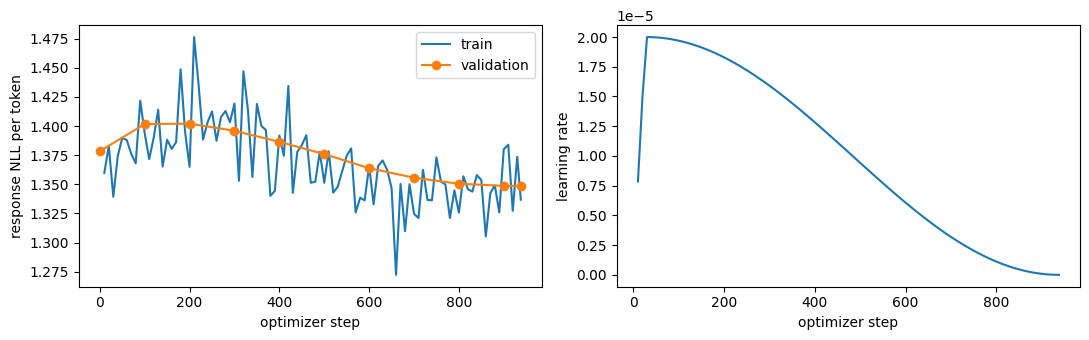

Checks passed


In [8]:
import json, math
import matplotlib.pyplot as plt

records = [json.loads(line) for line in open(f"{OUTPUT_DIR}/metrics.jsonl")]
train = [r for r in records if r["type"] == "train"]
evals = [r for r in records if r["type"] == "eval"]

print("Validation loss by step:")
for r in evals:
    print(f"  step {r['step']:>5}  val_loss {r['val_loss']:.4f}  ppl {r['val_ppl']:.2f}" + ("  (baseline, untrained)" if r.get("baseline") else "") + ("  (best so far)" if r.get("best_so_far") else ""))
print(f"\nLast train loss {train[-1]['train_loss']:.4f} | grad_norm {train[-1]['grad_norm']:.3f} | "
      f"peak GPU mem {max(r.get('max_mem_gb', 0) for r in train):.2f} GB | {train[-1]['elapsed_min']} min")
print(json.load(open(f"{OUTPUT_DIR}/summary.json")))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot([r["step"] for r in train], [r["train_loss"] for r in train], label="train")
axes[0].plot([r["step"] for r in evals], [r["val_loss"] for r in evals], "o-", label="validation")
axes[0].set_xlabel("optimizer step"); axes[0].set_ylabel("response NLL per token"); axes[0].legend()
axes[1].plot([r["step"] for r in train], [r["lr"] for r in train])
axes[1].set_xlabel("optimizer step"); axes[1].set_ylabel("learning rate")
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/loss_curves.png", dpi=150)
plt.show()

# Pass criteria
assert all(math.isfinite(r["train_loss"]) for r in train), "NaN/inf in training loss"
if MODE == "overfit":
    first, last = train[0]["train_loss"], train[-1]["train_loss"]
    print(f"overfit: train loss {first:.3f} -> {last:.3f}")
    assert last < 0.5 * first, "could not memorize 32 examples: look for a bug in the loss/optimizer path"
elif MODE == "full":
    assert min(r["val_loss"] for r in evals[1:]) < evals[0]["val_loss"], "validation loss never beat the untrained model"
# (pilot: 20 steps is too short for val loss to be meaningful, so it is not asserted)
assert os.path.isdir(f"{OUTPUT_DIR}/best") and os.path.isdir(f"{OUTPUT_DIR}/final"), "missing checkpoint"
print("Checks passed")

## 7. Quick look at what the model generates

Not the real evaluation (that's the generation notebook). Just a sanity check that the checkpoint reloads and answers in the trained format. After a 20-step pilot, expect only small changes.

In [9]:
import sys
sys.path.insert(0, REPO_DIR)
from transformers import AutoModelForCausalLM, AutoTokenizer
from src.alignment.formatting import format_prompt

ckpt = f"{OUTPUT_DIR}/best"
tok = AutoTokenizer.from_pretrained(ckpt)
model = AutoModelForCausalLM.from_pretrained(ckpt, torch_dtype=torch.float16).to("cuda:0").eval()

for instruction in ["Give three tips for staying focused while studying.",
                    "Explain what a hash table is in two sentences.",
                    "Write a haiku about rain."]:
    ids = tok(format_prompt(instruction), return_tensors="pt").to("cuda:0")
    with torch.no_grad():
        out = model.generate(**ids, max_new_tokens=150, do_sample=False, repetition_penalty=1.1,
                             pad_token_id=tok.eos_token_id)
    print("###", instruction)
    print(tok.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True).strip(), "\n")

del model; torch.cuda.empty_cache()

The tokenizer you are loading from '/kaggle/working/small-model-alignment/outputs/sft/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
`torch_dtype` is deprecated! Use `dtype` instead!


### Give three tips for staying focused while studying.
1. Set a study schedule: Create a study schedule that includes specific times and days to dedicate to studying. This will help you stay on track and avoid procrastination.

2. Minimize distractions: Turn off notifications on your phone or computer, close unnecessary tabs, and find a quiet place to study. Avoid multitasking as it can lead to distraction and decrease productivity.

3. Take breaks: Taking short breaks throughout the day can help refresh your mind and increase focus. Try taking a walk, doing some stretching, or meditating before starting your studies. 

### Explain what a hash table is in two sentences.
A hash table is a data structure that uses a mapping function to associate keys with values. It allows for fast retrieval of data based on the key, which can be used to quickly access and manipulate data within the table. 

### Write a haiku about rain.
Raindrops dance on the ground,
Nature's symphony of life. 



## 8. Package outputs (full run only)

In [10]:
import zipfile, glob

if MAKE_ZIP:
    zip_path = f"/kaggle/working/{RUN_NAME}_run_outputs.zip"
    # ZIP_STORED: no compression, so the ~2 GB checkpoints are copied quickly
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_STORED) as zf:
        for path in glob.glob(f"{OUTPUT_DIR}/**/*", recursive=True):
            if os.path.isfile(path):
                zf.write(path, os.path.relpath(path, os.path.dirname(OUTPUT_DIR)))
    print("wrote", zip_path, f"{os.path.getsize(zip_path)/1e9:.2f} GB")
else:
    print("Pilot run: skipping zip")

!du -sh {OUTPUT_DIR}/* 2>/dev/null
!df -h /kaggle/working | tail -1

wrote /kaggle/working/sft_run_outputs.zip 3.99 GB
1.9G	/kaggle/working/small-model-alignment/outputs/sft/best
4.0K	/kaggle/working/small-model-alignment/outputs/sft/config.json
1.9G	/kaggle/working/small-model-alignment/outputs/sft/final
104K	/kaggle/working/small-model-alignment/outputs/sft/loss_curves.png
24K	/kaggle/working/small-model-alignment/outputs/sft/metrics.jsonl
4.0K	/kaggle/working/small-model-alignment/outputs/sft/summary.json
2.2M	/kaggle/working/small-model-alignment/outputs/sft/train_ids.jsonl
2.8M	/kaggle/working/small-model-alignment/outputs/sft/val_split.jsonl
/dev/loop2       20G  7.5G   13G  39% /kaggle/working
